In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_25172\2084090043.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [6]:
adl_data = np.load(WORKDIR+'/Data/UNIMIB-SHAR/adl_data.npy',allow_pickle=True)

In [7]:
adl_data = pd.DataFrame(adl_data)

In [8]:
adl_data.head()

,0,1,2,3,4,5,6,7,8,9,...,443,444,445,446,447,448,449,450,451,452
0,7.609005,7.322882,7.281458,7.753253,8.043099,8.215854,8.388745,8.578034,8.658356,8.670648,...,-6.372120,-6.323450,-6.474440,-6.449742,-6.415010,-6.514918,-6.590504,-6.535514,-6.453252,-6.182647
1,8.507709,8.480922,8.747757,8.863954,8.863968,8.458413,7.782317,7.412026,7.589061,7.709209,...,-6.785400,-6.583993,-6.291560,-6.472510,-6.626783,-6.774500,-6.929722,-6.846734,-6.704524,-6.513264
2,8.442040,8.632098,8.730012,8.697698,8.552650,8.057508,0.395888,-0.090756,-0.335575,-0.507582,...,-6.403487,-6.450791,-6.612762,-6.830472,-6.872514,-7.249798,-7.414935,-7.278581,-7.127102,-6.832014
3,-11.025566,-11.714652,-11.765208,-9.944634,-7.660169,-6.882160,-7.601299,-9.161294,-10.339050,-11.046978,...,-7.715563,-7.764263,-7.755619,-8.040819,-8.091955,-7.817943,-7.768974,-7.687118,-7.795514,-7.819323
4,0.238472,0.321549,0.383802,0.495767,0.664556,0.776264,1.019609,1.010645,0.850412,0.473916,...,-7.614920,-7.553618,-7.381002,-7.324491,-7.473060,-7.441543,-7.546224,-7.474858,-7.441730,-7.412475


In [9]:
import pandas as pd

def transform_unimib_shar_data(original_df, output_file_path):
    """
    Transforms UniMiB SHAR dataset to linearize accelerometer data into 
    columns for x, y, and z, saving the result as a CSV file.
    
    Args:
        original_df (pd.DataFrame): The original dataset loaded as a DataFrame.
        output_file_path (str): Path to save the transformed CSV file.
    
    Returns:
        pd.DataFrame: The transformed DataFrame.
    """
    new_columns = ['Acc_X', 'Acc_Y', 'Acc_Z']
    transformed_data = []  # Collect data row by row
    
    # Process each row: extract accelerometer data assuming a fixed structure
    for index in range(0, original_df.shape[0], 3):  # Step in chunks of 3 rows
        # Ensure we don't go out of bounds
        if index + 2 >= original_df.shape[0]:
            break
        
        acc_x = original_df.iloc[index].values
        acc_y = original_df.iloc[index + 1].values
        acc_z = original_df.iloc[index + 2].values
        
        # Transpose and collect as rows for x, y, z
        for i in range(len(acc_x)):
            transformed_data.append([acc_x[i], acc_y[i], acc_z[i]])
    
    # Convert the collected data into a DataFrame
    transformed_df = pd.DataFrame(transformed_data, columns=new_columns)
    
    # Save to a CSV file
    transformed_df.to_csv(output_file_path, index=False)
    print(f"Transformed data has been saved to {output_file_path}")

    return transformed_df

# Example usage:
# transformed_df = transform_unimib_shar_data(original_df, "transformed_data.csv")


In [10]:
transformed_df = transform_unimib_shar_data(adl_data,"unimib_shar_dataset_transformed.csv")

Transformed data has been saved to unimib_shar_dataset_transformed.csv


In [12]:
transformed_df.tail()

,Acc_X,Acc_Y,Acc_Z
1144273,1.149011,-0.185326,-0.422122
1144274,1.159295,-0.223396,-0.403630
1144275,1.129326,-0.195890,-0.357143
1144276,1.128397,-0.084954,-0.345482
1144277,1.072502,-0.088815,-0.383802


In [4]:
data.shape

(20750, 1803)

In [5]:
data.tail()

,0,1,2,3,4,5,6,7,8,9,...,1793,1794,1795,1796,1797,1798,1799,1800,1801,1802
20745,1.8716,1.6488,1.60890,1.80230,1.47500,1.390700,1.13780,1.28960,0.96375,1.022200,...,-0.49764,-0.43259,-0.414760,-0.363110,-0.329190,-0.460960,-0.621920,9,300,20746
20746,1.8894,2.0227,0.81730,-0.50584,2.46220,3.814200,2.66100,2.65120,1.99140,4.427300,...,-0.20882,-0.28893,-0.320880,-0.379540,-0.408210,-0.507970,-0.548040,9,300,20747
20747,1.2695,1.3122,0.72557,0.53129,0.95842,-0.049679,1.22310,1.83700,0.98974,1.882600,...,1.21850,1.12540,0.639470,0.277320,0.172710,-0.002894,0.023955,9,300,20748
20748,-5.5622,-2.7970,-2.35330,-3.07560,-4.13610,-4.028800,-0.58026,0.34607,-2.63170,-2.790000,...,-0.24667,-0.20902,-0.128670,-0.104730,-0.131960,-0.150780,-0.187320,9,300,20749
20749,0.8381,-1.2116,-0.56718,-0.55532,-0.64496,-0.232160,0.36707,-0.04070,0.18598,-0.009721,...,0.26162,0.11912,0.004095,0.006755,0.013448,0.027566,0.140510,9,300,20750


In [6]:
data = data[data[1800].isin([0,1,4,5,6])]

In [7]:
data.shape

(9513, 1803)

In [8]:
data[1800].value_counts().sort_index()

1800
0    1886
1    1874
4    2178
5    1813
6    1762
Name: count, dtype: int64

In [9]:
# Define the mapping dictionary
mapping_dict = {4:2,5:3,6:4}

In [10]:
data = data.replace(to_replace=mapping_dict)


In [11]:
data[1800].value_counts().sort_index()

1800
0    1886
1    1874
2    2178
3    1813
4    1762
Name: count, dtype: int64

In [12]:
X = data.iloc[:, :-3]

In [13]:
y = data.iloc[:,-3]

In [14]:
X_train_data, X_validation_data, labels_train, labels_val = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# **Data Exploration**

In [15]:
X_train_data.shape

(6659, 1800)

In [16]:
labels_train.shape

(6659,)

In [17]:
X_validation_data.shape


(2854, 1800)

In [18]:
labels_val.shape

(2854,)

In [19]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(_x_data, label_data):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = _x_data
    y = label_data

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote)) 
    print(X_smote.shape) 
    print(X_smote.shape) 

    return X_smote, y_smote

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [21]:
X_train_data,labels_train = balance_data_with_smote(X_train_data,labels_train.values)

Before SMOTE: Counter({2: 1521, 1: 1342, 0: 1300, 3: 1272, 4: 1224})
After SMOTE: Counter({1: 1521, 2: 1521, 4: 1521, 0: 1521, 3: 1521})
(7605, 1800)
(7605, 1800)


In [22]:
print(X_train_data.shape)
print(labels_train.shape)

(7605, 1800)
(7605,)


# **Models**

In [23]:
labels_val_categorical = to_categorical(labels_val,num_classes=5)

In [24]:
print(labels_val_categorical)

[[0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 ...
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]]


In [25]:
print(labels_val_categorical.shape)

(2854, 5)


In [26]:
#print(occurrence_transitions_slide)

In [27]:
labels_train_categorical = to_categorical(labels_train,num_classes=5)

In [28]:
print(labels_train_categorical)

[[0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [29]:
print(labels_train_categorical.shape)

(7605, 5)


In [30]:
X_train = X_train_data
y_train = labels_train_categorical
X_validation = X_validation_data
y_validation = labels_val_categorical

In [31]:
X_train = X_train.values

In [32]:
X_train = np.expand_dims(X_train, axis=-2) 

In [33]:
X_train.shape

(7605, 1, 1800)

In [34]:
X_validation = X_validation.values

In [35]:
X_validation = np.expand_dims(X_validation, axis=-2) 

In [36]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(7605, 1, 1800)
(7605, 5)
(2854, 1, 1800)
(2854, 5)


In [37]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [38]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [39]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(7605, 1, 1800)
(7605, 5)
(2854, 1, 1800)
(2854, 5)


In [40]:
#from tensorflow.keras import regularizers

In [41]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [42]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [43]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(1,1800))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [44]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [45]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [46]:
tuner.search(x=X_train,
            y=y_train,
            epochs=100,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [00h 09m 10s]
val_accuracy: 0.8679047226905823

Best val_accuracy So Far: 0.8679047226905823
Total elapsed time: 00h 25m 12s


In [47]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-20_19-39-09\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 4 summary
Hyperparameters:
input_units_lstm1: 480
l2_reg1: 0.0015159319577885927
learning_rate: 0.008547485565344062
Score: 0.8679047226905823

Trial 2 summary
Hyperparameters:
input_units_lstm1: 288
l2_reg1: 0.0013607174450468629
learning_rate: 0.0009887195863122636
Score: 0.8304134607315063

Trial 0 summary
Hyperparameters:
input_units_lstm1: 352
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Score: 0.8083391785621643

Trial 3 summary
Hyperparameters:
input_units_lstm1: 128
l2_reg1: 0.0905127409782462
learning_rate: 0.001715074355925934
Score: 0.7771548628807068

Trial 1 summary
Hyperparameters:
input_units_lstm1: 160
l2_reg1: 0.05977728042983696
learning_rate: 0.000505466655750672
Score: 0.702873170375824


In [48]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 480,
 'l2_reg1': 0.0015159319577885927,
 'learning_rate': 0.008547485565344062}

In [49]:
best_model = tuner.get_best_models(num_models=1)[0]

In [50]:
best_model.history

In [51]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 1, 1800)]            0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 1, 480)               4379520   ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 1, 480)               230880    ['lstm[0][0]']                
                                                                                                  
 attention (Attention)       (None, 1, 480)               0         ['dense[0][0]',               
                                                                     'dense[0][0]']           

In [52]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

90/90 [==============================] - 2s 12ms/step - loss: 0.4897 - accuracy: 0.8679


In [53]:
predictions = best_model.predict(X_validation)

90/90 [==============================] - 2s 9ms/step


In [54]:
print(y_validation)

[[0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 ...
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]]


In [55]:
print(y_validation.shape)

(2854, 5)


In [56]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [57]:
print(y_validation_inverse)

[3 2 3 ... 1 1 4]


In [58]:
print(len(y_validation_inverse))

2854


In [59]:
print(predictions)

[[1.2884949e-10 1.4466259e-06 2.3758433e-04 9.9970716e-01 5.3732248e-05]
 [1.8171597e-18 3.0503696e-22 9.9999762e-01 6.7084302e-20 2.4398082e-06]
 [1.0292866e-04 7.6626102e-04 1.1970956e-04 9.9896216e-01 4.8849557e-05]
 ...
 [1.0652306e-01 8.9315534e-01 1.4595433e-04 9.5201816e-05 8.0498314e-05]
 [1.0219643e-01 8.0522168e-01 2.1218196e-02 6.7850091e-02 3.5136254e-03]
 [2.2698063e-15 1.5470816e-31 1.1449665e-05 1.1952498e-17 9.9998856e-01]]


In [60]:
classes_x=np.argmax(predictions,axis=1)

In [61]:
print(classes_x)

[3 2 3 ... 1 1 4]


In [62]:
print(len(classes_x))

2854


In [63]:
print(classes_x.shape)

(2854,)


In [64]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [65]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

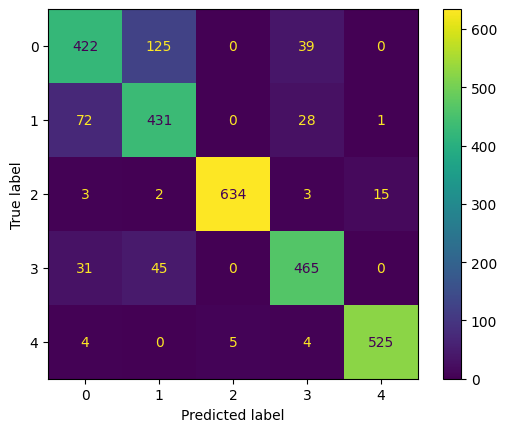

In [66]:
disp.plot()

In [67]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.79      0.72      0.75       586
           1       0.71      0.81      0.76       532
           2       0.99      0.96      0.98       657
           3       0.86      0.86      0.86       541
           4       0.97      0.98      0.97       538

    accuracy                           0.87      2854
   macro avg       0.87      0.87      0.87      2854
weighted avg       0.87      0.87      0.87      2854



In [3]:
# Updated transformation function to include saving the result to a CSV file
def transform_dataframe_corrected_with_save(original_df, output_file_path):
    # Step 1: Remove columns 1801 and 1802
    reduced_df = original_df.drop(columns=[1801, 1802])
    
    # Step 2: Create a new DataFrame with 6 columns and a label column
    new_columns = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Label']
    transformed_data = []  # Use a list to collect data for better performance
    
    # Step 3: Process each row in the original DataFrame
    for index, row in reduced_df.iterrows():
        class_id = row[1800]  # Get the class ID
        for i in range(0, 900, 300):  # Iterate over the 3 segments of accelerometer columns
            for j in range(0, 300, 3):  # Get chunks of 3 data points
                acc_x, acc_y, acc_z = row[i + j], row[i + j + 1], row[i + j + 2]
                gyro_x, gyro_y, gyro_z = row[900 + i + j], row[900 + i + j + 1], row[900 + i + j + 2]
                # Append the new row as a list
                transformed_data.append([acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, class_id])
    
    # Convert the collected data into a DataFrame
    transformed_df = pd.DataFrame(transformed_data, columns=new_columns)
    
    # Save to a CSV file
    transformed_df.to_csv(output_file_path, index=False)
    print(f"Transformed data has been saved to {output_file_path}")

    return transformed_df

# Example usage (assuming you have the original_df loaded):
# transformed_df = transform_dataframe_corrected_with_save(original_df, "transformed_data.csv")


In [5]:
transformed_df = transform_dataframe_corrected_with_save(data,"kuhar_dataset_transformed.csv")

Transformed data has been saved to kuhar_dataset_transformed.csv


In [8]:
transformed_df.tail(1000)

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
6224000,-1.544100,-1.455400,-1.342600,-0.670250,-0.793300,-0.862170,9.0
6224001,-1.202100,-0.657180,-0.495870,-0.833940,-0.800140,-0.800190,9.0
6224002,-0.810940,0.412510,0.616960,-0.799540,-0.820110,-0.936200,9.0
6224003,-1.791000,-1.104100,-0.551270,-0.987590,-1.082200,-1.169200,9.0
6224004,-2.807900,-2.924700,-0.020243,-1.154600,-1.109700,-1.052500,9.0
...,...,...,...,...,...,...,...
6224995,0.810590,-0.260730,-0.423510,0.201280,0.202320,0.256590,9.0
6224996,-0.118410,-0.584860,-0.303600,0.297490,0.319670,0.367400,9.0
6224997,0.695130,0.372170,-0.161830,0.353460,0.290810,0.261620,9.0
6224998,0.097524,-0.074573,-1.568400,0.119120,0.004095,0.006755,9.0


In [10]:
transformed_df.shape

(6225000, 7)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)